Data 620 Week 6 Assignment 

Yana Rabkova

In [1]:
import sys
import itertools
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite
from IPython.display import display

G = nx.davis_southern_women_graph()
women = G.graph['top']
events = G.graph['bottom']
assert nx.is_bipartite(G)
assert (len(women), len(events), G.number_of_edges()) == (18, 14, 89)
print(f'{len(women)} women, {len(events)} events, {G.number_of_edges()} attendance records')
A = pd.DataFrame([[int(G.has_edge(w, e)) for e in events] for w in women],
                 index=women, columns=events)
display(A)

18 women, 14 events, 89 attendance records


,E1,E2,E3,E4,E5,E6,E7,E8,E9,E10,E11,E12,E13,E14
Evelyn Jefferson,1,1,1,1,1,1,0,1,1,0,0,0,0,0
Laura Mandeville,1,1,1,0,1,1,1,1,0,0,0,0,0,0
Theresa Anderson,0,1,1,1,1,1,1,1,1,0,0,0,0,0
Brenda Rogers,1,0,1,1,1,1,1,1,0,0,0,0,0,0
Charlotte McDowd,0,0,1,1,1,0,1,0,0,0,0,0,0,0
Frances Anderson,0,0,1,0,1,1,0,1,0,0,0,0,0,0
Eleanor Nye,0,0,0,0,1,1,1,1,0,0,0,0,0,0
Pearl Oglethorpe,0,0,0,0,0,1,0,1,1,0,0,0,0,0
Ruth DeSand,0,0,0,0,1,0,1,1,1,0,0,0,0,0
Verne Sanderson,0,0,0,0,0,0,1,1,1,0,0,1,0,0


In [3]:

# Number of events attended by each woman
women_attendance = A.sum(axis=1).sort_values(ascending=False)

# Number of women attending each event
event_attendance = A.sum(axis=0).sort_values(ascending=False)

print("Events attended by each woman:")
display(women_attendance)

print("Number of attendees per event:")
display(event_attendance)


Events attended by each woman:


Evelyn Jefferson     8
Theresa Anderson     8
Nora Fayette         8
Laura Mandeville     7
Brenda Rogers        7
Sylvia Avondale      7
Katherina Rogers     6
Helen Lloyd          5
Myra Liddel          4
Verne Sanderson      4
Ruth DeSand          4
Eleanor Nye          4
Frances Anderson     4
Charlotte McDowd     4
Pearl Oglethorpe     3
Dorothy Murchison    2
Olivia Carleton      2
Flora Price          2
dtype: int64

Number of attendees per event:


E8     14
E9     12
E7     10
E5      8
E6      8
E3      6
E12     6
E10     5
E4      4
E11     4
E1      3
E2      3
E13     3
E14     3
dtype: int64

Evelyn Jefferson, Theresa Anderson and Nora Fayette attended the most amount of events. 

Even 8 was the most attended with 14 women. 

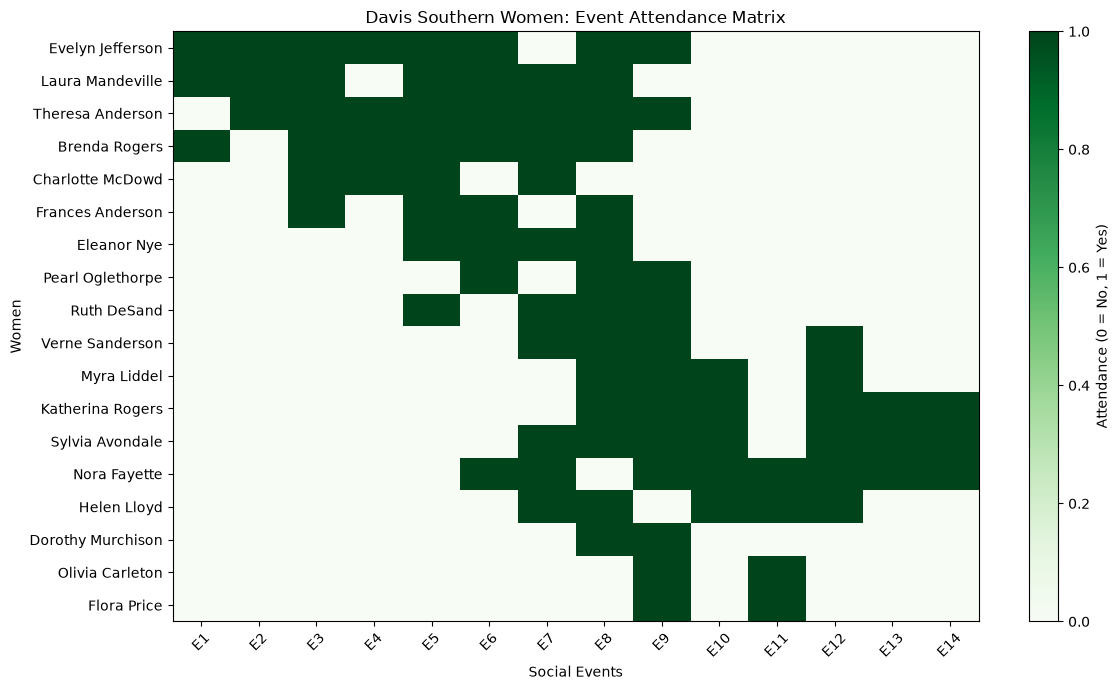

In [5]:

plt.figure(figsize=(12, 7))

plt.imshow(A, cmap="Greens", aspect="auto", interpolation="nearest")

plt.xticks(range(len(A.columns)), A.columns, rotation=45)
plt.yticks(range(len(A.index)), A.index)

plt.xlabel("Social Events")
plt.ylabel("Women")
plt.title("Davis Southern Women: Event Attendance Matrix")

plt.colorbar(label="Attendance (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()


The attendance matrix suggests two partially overlapping groups of women. The first group primarily attended earlier events (E1–E8), while the second group attended later events (E9–E14). Events E7–E9 appear to connect these groups, as they were attended by women with different participation patterns. This suggests that some events may have played an important role in connecting different social circles.

In [6]:
women_shared = A @ A.T

display(women_shared)

,Evelyn Jefferson,Laura Mandeville,Theresa Anderson,Brenda Rogers,Charlotte McDowd,Frances Anderson,Eleanor Nye,Pearl Oglethorpe,Ruth DeSand,Verne Sanderson,Myra Liddel,Katherina Rogers,Sylvia Avondale,Nora Fayette,Helen Lloyd,Dorothy Murchison,Olivia Carleton,Flora Price
Evelyn Jefferson,8,6,7,6,3,4,3,3,3,2,2,2,2,2,1,2,1,1
Laura Mandeville,6,7,6,6,3,4,4,2,3,2,1,1,2,2,2,1,0,0
Theresa Anderson,7,6,8,6,4,4,4,3,4,3,2,2,3,3,2,2,1,1
Brenda Rogers,6,6,6,7,4,4,4,2,3,2,1,1,2,2,2,1,0,0
Charlotte McDowd,3,3,4,4,4,2,2,0,2,1,0,0,1,1,1,0,0,0
Frances Anderson,4,4,4,4,2,4,3,2,2,1,1,1,1,1,1,1,0,0
Eleanor Nye,3,4,4,4,2,3,4,2,3,2,1,1,2,2,2,1,0,0
Pearl Oglethorpe,3,2,3,2,0,2,2,3,2,2,2,2,2,2,1,2,1,1
Ruth DeSand,3,3,4,3,2,2,3,2,4,3,2,2,3,2,2,2,1,1
Verne Sanderson,2,2,3,2,1,1,2,2,3,4,3,3,4,3,3,2,1,1


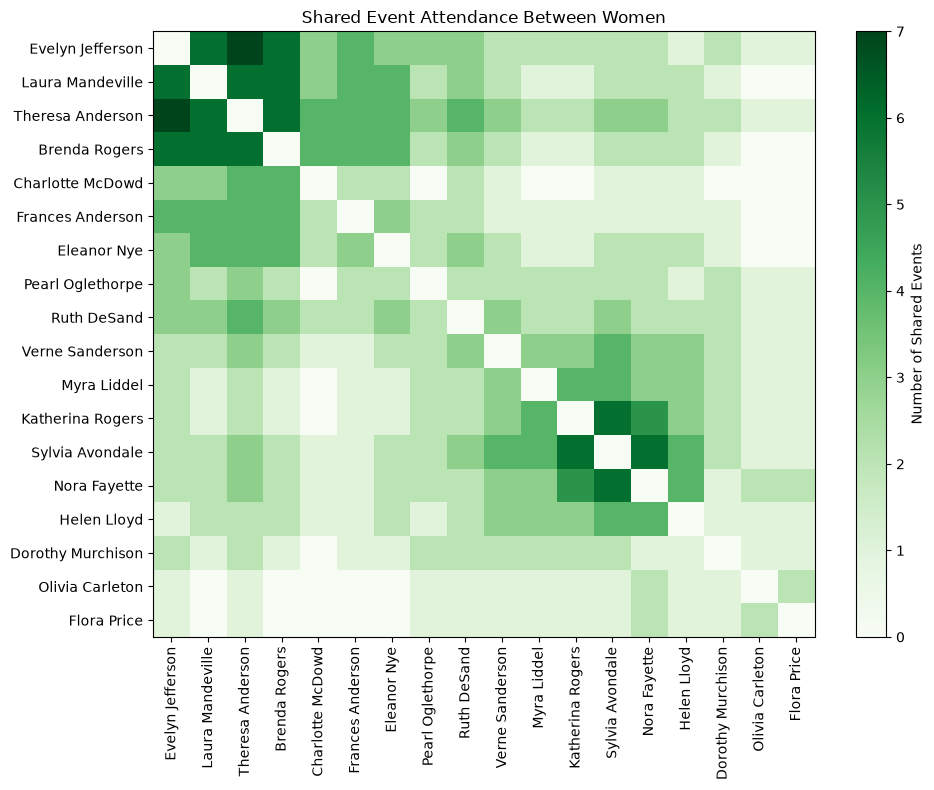

In [16]:

# Calculate shared events between women
women_shared = A @ A.T

# Remove diagonal values
for i in range(len(women_shared)):
    women_shared.iloc[i, i] = 0

# Create heatmap
plt.figure(figsize=(10, 8))

plt.imshow(women_shared, cmap="Greens", aspect="auto")

plt.xticks(range(len(women_shared.columns)),
           women_shared.columns, rotation=90)
plt.yticks(range(len(women_shared.index)),
           women_shared.index)

plt.colorbar(label="Number of Shared Events")
plt.title("Shared Event Attendance Between Women")
plt.tight_layout()
plt.show()



The shared attendance heatmap reveals two relatively distinct groups of women. Evelyn Jefferson, Laura Mandeville, Theresa Anderson, and Brenda Rogers have particularly strong connections, sharing up to seven events. Another group, including Katherine Rogers, Sylvia Avondale, and Nora Fayette, also shows strong shared attendance.

However, the groups are not completely separated. Several women have connections across both groups, suggesting some overlap between the social circles. Overall, the results indicate that women tended to attend events with similar groups of people, although shared attendance alone does not necessarily imply personal friendships.

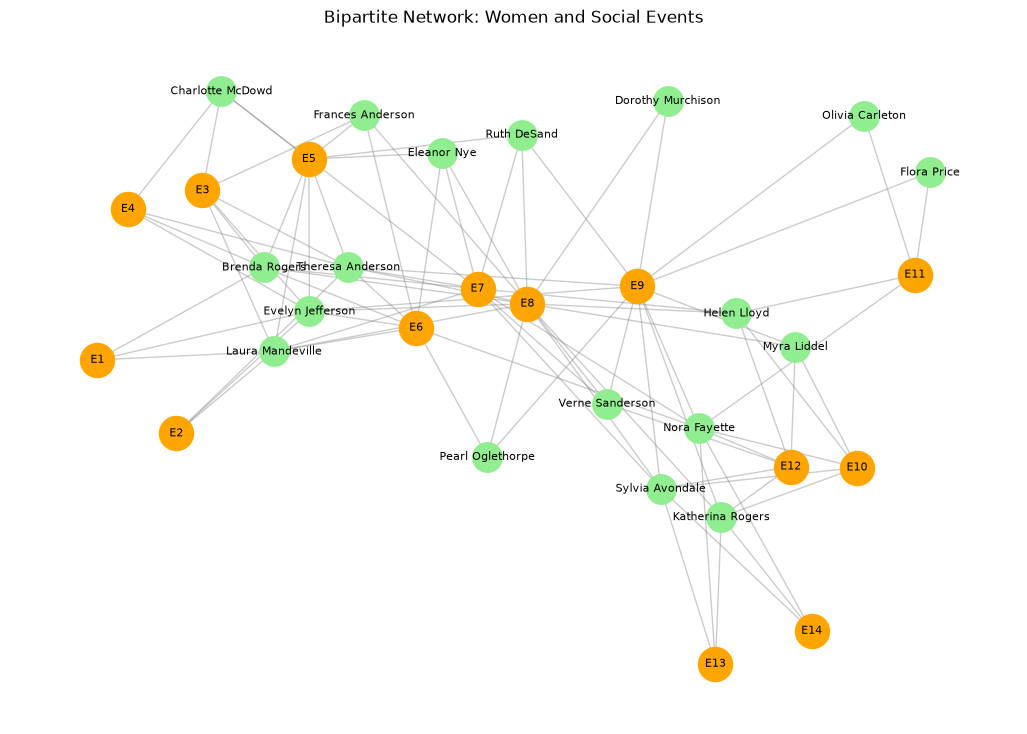

In [17]:

plt.figure(figsize=(13, 9))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G, pos, nodelist=women,
    node_color="lightgreen", node_size=450
)

nx.draw_networkx_nodes(
    G, pos, nodelist=events,
    node_color="orange", node_size=600
)

nx.draw_networkx_edges(
    G, pos, alpha=0.4, edge_color="gray"
)

nx.draw_networkx_labels(G, pos, font_size=8)

plt.title("Bipartite Network: Women and Social Events")
plt.axis("off")
plt.show()


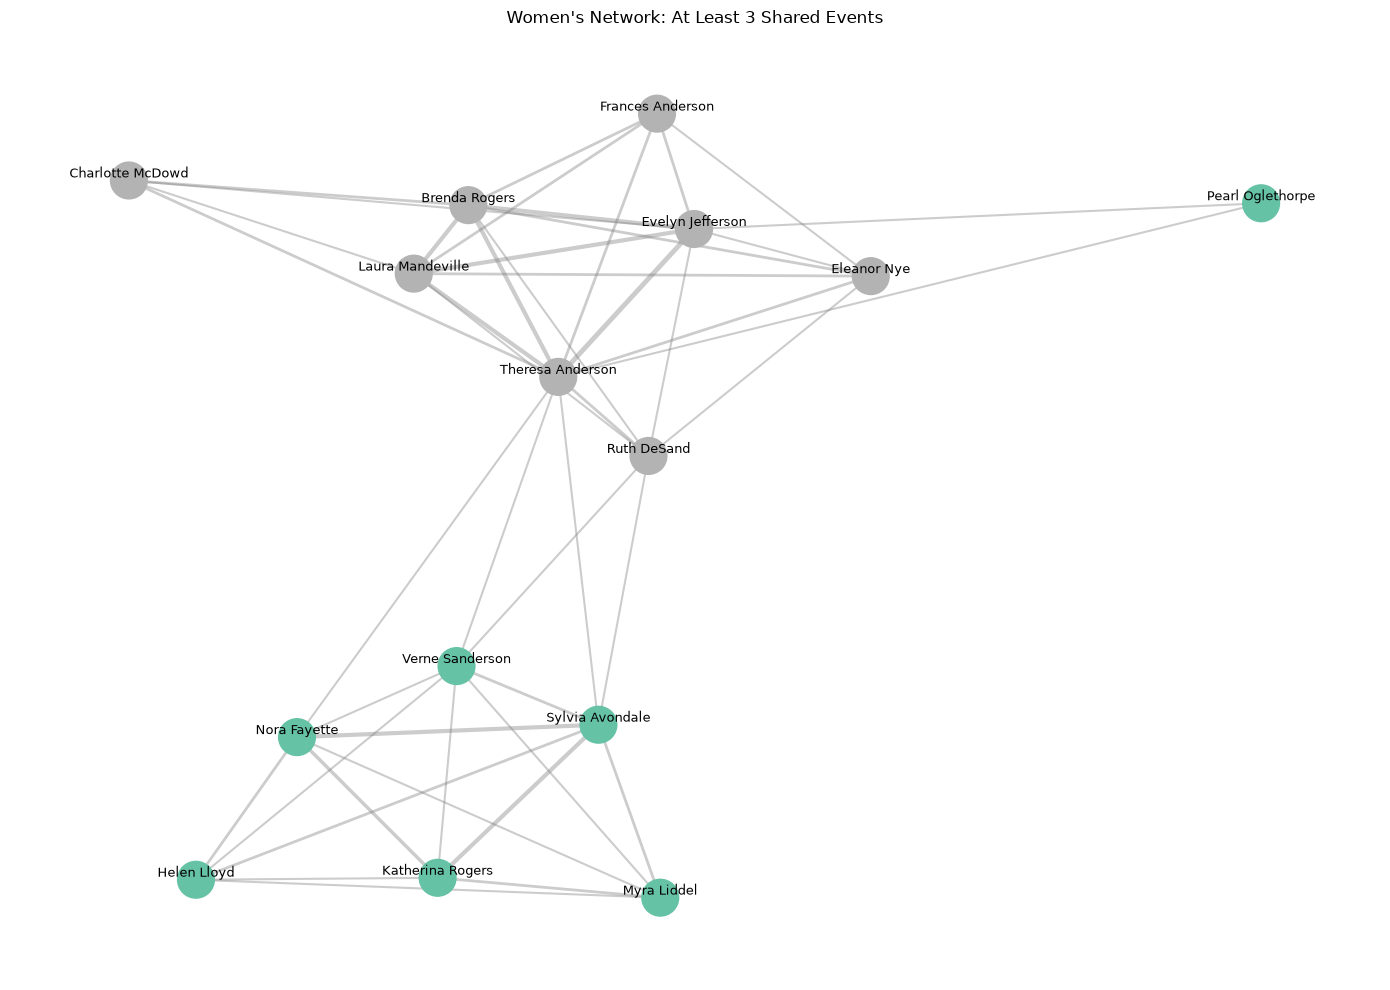

In [21]:

# Keep connections with at least 3 shared events
W_strong = nx.Graph()

W_strong.add_edges_from(
    (u, v, d)
    for u, v, d in W.edges(data=True)
    if d["weight"] >= 3
)

# Increase spacing between nodes
pos = nx.spring_layout(
    W_strong,
    k=1.5,
    iterations=200,
    seed=42
)

plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(
    W_strong, pos,
    node_color=[community_map[n] for n in W_strong.nodes()],
    cmap=plt.cm.Set2,
    node_size=700
)

nx.draw_networkx_edges(
    W_strong, pos,
    edge_color="gray",
    alpha=0.4,
    width=[d["weight"] * 0.5
           for u, v, d in W_strong.edges(data=True)]
)

nx.draw_networkx_labels(
    W_strong, pos,
    font_size=9,
    verticalalignment="bottom"
)

plt.title("Women's Network: At Least 3 Shared Events")
plt.axis("off")
plt.tight_layout()
plt.show()


In [22]:

# Count connections between different communities
cross_group = {}

for woman in W_strong.nodes():
    cross_group[woman] = sum(
        community_map[woman] != community_map[neighbor]
        for neighbor in W_strong.neighbors(woman)
    )

cross_group_df = pd.Series(
    cross_group, name="Cross-Community Connections"
).sort_values(ascending=False)

display(cross_group_df)


Theresa Anderson    4
Pearl Oglethorpe    2
Ruth DeSand         2
Sylvia Avondale     2
Verne Sanderson     2
Evelyn Jefferson    1
Nora Fayette        1
Eleanor Nye         0
Laura Mandeville    0
Brenda Rogers       0
Frances Anderson    0
Charlotte McDowd    0
Myra Liddel         0
Helen Lloyd         0
Katherina Rogers    0
Name: Cross-Community Connections, dtype: int64

The network analysis identified two communities based on shared event attendance. Although most strong connections occur within communities, some women also have connections across community boundaries. Theresa Anderson had the highest number of cross-community connections (4), followed by several women, including Pearl Oglethorpe (2). This suggests that Theresa Anderson may play an important role in connecting the two social groups.

In [26]:
betweenness = nx.betweenness_centrality(W)

betweenness_df = pd.Series(
    betweenness,
    name="Betweenness Centrality"
).sort_values(ascending=False)

print(betweenness_df)

Evelyn Jefferson     0.010122
Ruth DeSand          0.010122
Helen Lloyd          0.010122
Nora Fayette         0.010122
Sylvia Avondale      0.010122
Verne Sanderson      0.010122
Theresa Anderson     0.010122
Pearl Oglethorpe     0.005348
Myra Liddel          0.005348
Katherina Rogers     0.005348
Dorothy Murchison    0.005348
Eleanor Nye          0.002674
Frances Anderson     0.002674
Laura Mandeville     0.002674
Brenda Rogers        0.002674
Charlotte McDowd     0.000000
Olivia Carleton      0.000000
Flora Price          0.000000
Name: Betweenness Centrality, dtype: float64


In [24]:

# Betweenness centrality on filtered network
betweenness_strong = nx.betweenness_centrality(W_strong)

betweenness_strong_df = pd.Series(
    betweenness_strong,
    name="Betweenness Centrality"
).sort_values(ascending=False)

print(betweenness_strong_df.to_string())


Theresa Anderson    0.411905
Sylvia Avondale     0.116850
Verne Sanderson     0.116850
Ruth DeSand         0.096703
Nora Fayette        0.070330
Evelyn Jefferson    0.043407
Laura Mandeville    0.010440
Brenda Rogers       0.010440
Eleanor Nye         0.002198
Pearl Oglethorpe    0.000000
Frances Anderson    0.000000
Charlotte McDowd    0.000000
Myra Liddel         0.000000
Helen Lloyd         0.000000
Katherina Rogers    0.000000


Betweenness centrality was initially calculated on the full women's projected network, but the results showed very low values with several ties. This is likely because the network is highly connected, with many women sharing at least one event.

To explore stronger relationships, I repeated the analysis using a filtered network that included only pairs of women who attended at least three events together. Theresa Anderson had the highest betweenness centrality (0.412), substantially higher than Sylvia Avondale and Verne Sanderson (both 0.117).

Combined with her four cross-community connections, this suggests that Theresa Anderson may play an important role in connecting the two social groups. However, these findings depend on the selected attendance threshold and should be interpreted as structural relationships rather than evidence of personal friendships.

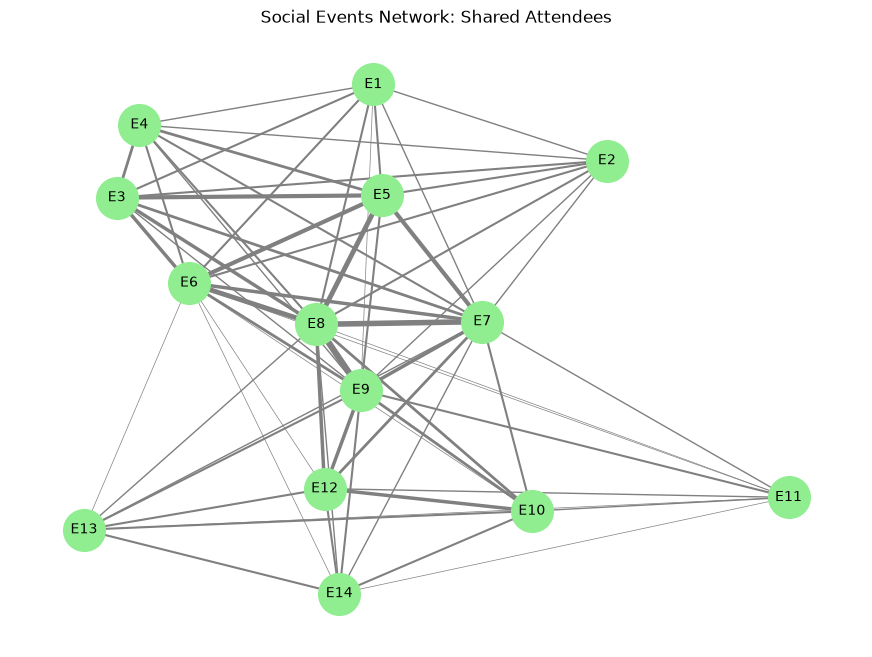

In [27]:

# Weighted projection onto events
E = bipartite.weighted_projected_graph(G, events)

pos = nx.spring_layout(E, weight="weight", seed=42)

plt.figure(figsize=(11, 8))

nx.draw_networkx(
    E, pos,
    node_color="lightgreen",
    node_size=900,
    edge_color="gray",
    width=[E[u][v]["weight"] * 0.5 for u, v in E.edges()],
    font_size=10
)

plt.title("Social Events Network: Shared Attendees")
plt.axis("off")
plt.show()


In [29]:

# Calculate weighted degree for each event
event_strength = dict(E.degree(weight="weight"))

event_strength_df = pd.DataFrame({
    "Event": list(event_strength.keys()),
    "Weighted Degree": list(event_strength.values())
})

event_strength_df = event_strength_df.sort_values(
    "Weighted Degree", ascending=False
)

print(event_strength_df)


   Event  Weighted Degree
7     E8               59
6     E7               48
8     E9               46
5     E6               41
4     E5               38
2     E3               32
11   E12               28
9    E10               25
3     E4               23
1     E2               20
0     E1               19
12   E13               18
13   E14               18
10   E11               13


In [30]:

# Create a copy of the events network
E_distance = E.copy()

# Convert connection strength into distance
for u, v, d in E_distance.edges(data=True):
    d["distance"] = 1 / d["weight"]

# Calculate weighted betweenness centrality
event_betweenness = nx.betweenness_centrality(
    E_distance,
    weight="distance"
)

event_betweenness_df = pd.Series(
    event_betweenness,
    name="Betweenness Centrality"
).sort_values(ascending=False)

print(event_betweenness_df.to_string())


E8     0.435897
E9     0.294872
E1     0.000000
E2     0.000000
E3     0.000000
E4     0.000000
E5     0.000000
E6     0.000000
E7     0.000000
E10    0.000000
E11    0.000000
E12    0.000000
E13    0.000000
E14    0.000000


The event network revealed that E8, E7, and E9 had the highest weighted degrees, indicating substantial overlap in attendees with other events. However, weighted betweenness centrality identified only E8 (0.436) and E9 (0.295) as intermediaries on shortest paths between events.

Interestingly, E7 had the second-highest weighted degree but zero betweenness centrality. This highlights the distinction between having many strong connections and occupying an important bridging position within a network.

Overall, E8 and E9 appear particularly important in connecting different parts of the event network, supporting the patterns observed in the earlier visualizations.

### Conclusion

The analysis of the Davis Southern Women network suggests two partially overlapping social groups based on shared event attendance. Women within each group tended to attend similar events, although connections between the groups were also present.

When focusing on stronger relationships (at least three shared events), Theresa Anderson emerged as an important connector between the communities, with the highest betweenness centrality (0.412).

The event network showed a similar pattern, with E8 and E9 having the highest weighted betweenness centrality, suggesting that these events occupy important positions connecting different parts of the network.

Overall, the analysis demonstrates how a bipartite network can reveal relationships between both individuals and events. However, shared attendance does not necessarily indicate personal friendships, and some findings depend on how connections are defined.